# Spikecurate

_via regression model_

**author**: laquitainesteeve@gmail.com

**purpose**: show the weights of the regression model that classifies the "good" units (>80% agreement score) amongst the sorted single-units, for the first 10 min of the biophysical simulation in the spontaneous regime (fig5g). 

**tested on**:

* Ubuntu 24.04.1 LTS (32 cores, 188 GB RAM, Intel(R) Core(TM) i9-14900K ＠3.2 GHz/5.8 GHz) with RTX 5090 GPU with 40GB VRAM (GPU not needed)

**Method**
- kilosort4's sorting extractor was generated with rtx5090 GPU, so the results slightly change from the original Tesla V100
- a dataset dataframe that contains the sorted single-units (indices), their quality metrics and their quality label ("good" or "bad" units evaluated with our ground truth, columns)

**Execution time**: 3 min


## Setup 

1. Create and activate envs/spikebias.yml

In [1]:
# automatically reload notebook
%load_ext autoreload
%autoreload 2

# import built-in packages
import os

# limit BLAS/OpenMP threads per worker, BEFORE numpy is imported (restart the kernel
# if numpy was already imported): the PCA runs ~20x faster than with default threads
# Each worker runs many small PCA fits, each fit makes many BLAS/LAPACK calls, by 
# default each call can use up to 32 threads. We capped that to 1 thread, which 
# substantially removed overhead and sped up compute.
# 2 min instead of 1.5h
for var in ["OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS"]:
    os.environ[var] = "1"
    
import shutil
import pickle
import copy
import random
import pandas as pd
import spikeinterface as si
import spikeinterface.preprocessing as spre
import spikeinterface.core.template_tools as ttools
from spikeinterface import comparison
from spikeinterface.curation import remove_excess_spikes
from spikeinterface import extract_waveforms
from spikeinterface.postprocessing import compute_principal_components
from spikeinterface.qualitymetrics import compute_quality_metrics as qm
import statsmodels.api as sm
from statsmodels.tools.validation import float_like
import torch
import numpy as np
from matplotlib import pyplot as plt
import sklearn
import seaborn as sns
from sklearn import metrics
from sklearn.preprocessing import StandardScaler
import warnings
import spikecurate 

# silence irrelevant warnings
warnings.filterwarnings("ignore", message="There is no Probe attached to this recording.*")
warnings.filterwarnings("ignore", message="Versions are not the same.*")

# spikeinterface version
print("Spikeinterface", si.__version__)

# set project path
proj_path = "/home/steeve/steeve/epfl/code/spikebias/"
os.chdir(proj_path)

# import custom package
# (helpers that read sorting_quality.csv are not in the spikecurate package)
from src.nodes.models.Flc import dataloader

# experiment parameters
EXP = "NS"
SORTER = "KS4"

# waveform extraction parameters
FREQ_MIN = 300
REFERENCE = "global"
OPERATOR = "median"
MS_BEFORE = 6
MS_AFTER = 6
LOAD_WE = False
DURATION_SEC = 600          # 10 minutes recording
MAX_SPIKES_PER_UNIT = 500   # max number of spikes used per unit
SEED = 0
N_COMP_PCA = 5              # number of pca components
SPARSE = True
OVERWRITE = True
WE_JOB_KWARGS = dict(n_jobs=20, chunk_duration="1s", progress_bar=True)
job_kwargs = dict(n_jobs=-1, progress_bar=True)

CHUNKS = 80000 # for waveform extractor

# model parameters
model_prms = {"seeds": np.arange(0,100,1), "scale_data": False}

# recording extractor
RECORDING_PATH = "dataset/00_raw/recording_npx_spont/"

# kilosort sorting extractor
SORTING_KS4_PATH = "dataset/01_intermediate/sorting/npx_spont/SortingKS4_10m/"

# ground truth extractors
SORTING_TRUE = "dataset/00_raw/ground_truth_npx_spont"
SORTING_TRUE_10mn = "dataset/00_raw/ground_truth_npx_spont_10m"

# waveform extractors
# WE_PATH = "dataset/01_intermediate/waveforms/npx_spont/SortingKS4_10m/"
WE_SINGLE_U_PATH = "dataset/01_intermediate/waveforms/npx_spont/SortingKS4_10m_single_units"

# unit classification
QUALITY_PATH = "dataset/01_intermediate/analysis/sorting_quality/sorting_quality.csv"

# figure parameters
plt.rcParams["font.family"] = "Arial"
plt.rcParams["font.size"] = 6  # 5-7 with Nature neuroscience as reference
plt.rcParams["lines.linewidth"] = 0.5 # typically between 0.5 and 1
plt.rcParams["axes.linewidth"] = 0.5 
plt.rcParams["axes.spines.top"] = False
plt.rcParams["xtick.major.width"] = 0.5
plt.rcParams["xtick.minor.width"] = 0.5
plt.rcParams["ytick.major.width"] = 0.5
plt.rcParams["ytick.minor.width"] = 0.5
plt.rcParams["xtick.major.size"] = 3.5 * 1.1
plt.rcParams["xtick.minor.size"] = 2 * 1.1
plt.rcParams["ytick.major.size"] = 3.5 * 1.1
plt.rcParams["ytick.minor.size"] = 2 * 1.1

# figure legend parameters
legend_cfg = {"frameon": False, "handletextpad": 0.5}
tight_layout_cfg = {"pad": 0.001}
LG_FRAMEON = False              # no legend frame

Spikeinterface 0.100.8


## Load datasets

* Execution time: 27 ms

### Recording extractor

* Execution time: 

In [2]:
%%time

# load and preprocess recording
Recording = si.load_extractor(RECORDING_PATH)
Recording.set_property('location', Recording.get_property('location')[:,:2])
Recording = spre.highpass_filter(Recording, freq_min=FREQ_MIN)
Recording = spre.common_reference(Recording, reference=REFERENCE, operator=OPERATOR)
# keep the first 10 min so that the recording duration matches the sorting
# (duration-dependent quality metrics: firing_rate, firing_range, presence_ratio)
Recording = Recording.frame_slice(start_frame=0, end_frame=int(Recording.get_sampling_frequency() * DURATION_SEC))
display(Recording)

FrameSliceRecording: 384 channels - 40.0kHz - 1 segments - 24,000,000 samples 
                     600.00s (10.00 minutes) - float32 dtype - 34.33 GiB

CPU times: user 4.52 ms, sys: 80 µs, total: 4.6 ms
Wall time: 4.38 ms


### Ground truth extractor

* Execution time: 

In [3]:
%%time

# load ground truth
SortingTrue = si.load_extractor(SORTING_TRUE)
SortingTrue = SortingTrue.frame_slice(start_frame=0, end_frame=int(Recording.get_sampling_frequency() * DURATION_SEC))
SortingTrue.save(folder=SORTING_TRUE_10mn, overwrite=True)
display(SortingTrue)

FrameSliceSorting: 1388 units - 1 segments - 40.0kHz

CPU times: user 239 ms, sys: 10.1 ms, total: 250 ms
Wall time: 249 ms


### Sorting extractor

* Execution time: 20 ms

In [4]:
%%time

# load sorting
Sorting = si.load_extractor(SORTING_KS4_PATH)
Sorting = remove_excess_spikes(Sorting, Recording)
Sorting = Sorting.frame_slice(start_frame=0, end_frame=Recording.get_sampling_frequency() * DURATION_SEC)
display(Sorting)

FrameSliceSorting: 520 units - 1 segments - 40.0kHz

CPU times: user 1.89 ms, sys: 0 ns, total: 1.89 ms
Wall time: 1.64 ms


### Waveform extractor (Sorted units)

* Execution time: 2.5 min

In [5]:
%%time 

# select sorted single-units amongst single- and multi-units (KSLABEL="good" for kilosort4)
single_unit_ids = Sorting.unit_ids[np.where(Sorting.get_property("KSLabel") == "good")[0]]
Sorting_single_units = Sorting.select_units(unit_ids=single_unit_ids)

# save their waveforms
We_single_u = extract_waveforms(Recording, Sorting_single_units, WE_SINGLE_U_PATH, mode="folder", sparse=SPARSE, ms_before=MS_BEFORE,
                    ms_after=MS_AFTER, max_spikes_per_unit=MAX_SPIKES_PER_UNIT, unit_batch_size=CHUNKS,
                    overwrite=OVERWRITE, seed=SEED, **WE_JOB_KWARGS)


# save waveform PCA data (the extractor is updated)
pca = compute_principal_components(waveform_extractor=We_single_u, n_components=N_COMP_PCA, mode="by_channel_local", **WE_JOB_KWARGS)

extract waveforms shared_memory multi buffer:   0%|          | 0/600 [00:00<?, ?it/s]

extract waveforms memmap multi buffer:   0%|          | 0/600 [00:00<?, ?it/s]

Fitting PCA:   0%|          | 0/184 [00:00<?, ?it/s]

Projecting waveforms:   0%|          | 0/184 [00:00<?, ?it/s]

CPU times: user 25.1 s, sys: 43.2 s, total: 1min 8s
Wall time: 2min 26s


### Single-unit ids and labels (good/gad)

In [6]:
%%time

# label "good" and "bad" sorted single-units to train the classifier
good_unit_ids, bad_unit_ids = dataloader.get_good_and_bad_units(QUALITY_PATH, exp="NS", sorter="KS4")

# report
print("\nSingle-unit ids:", single_unit_ids)
print("\nGood unit ids:", good_unit_ids)
print("\nBad unit ids:", bad_unit_ids)


Single-unit ids: ['26' '29' '40' '41' '42' '45' '48' '53' '54' '55' '56' '58' '60' '61'
 '66' '71' '76' '77' '81' '83' '84' '85' '86' '90' '96' '102' '104' '105'
 '108' '109' '110' '113' '116' '117' '120' '121' '122' '126' '127' '128'
 '130' '135' '140' '142' '143' '146' '149' '152' '157' '158' '160' '162'
 '165' '166' '172' '183' '189' '193' '197' '198' '199' '201' '202' '207'
 '211' '213' '214' '221' '223' '227' '231' '239' '240' '241' '247' '249'
 '250' '252' '254' '262' '263' '264' '269' '270' '277' '280' '281' '283'
 '284' '286' '289' '291' '292' '296' '297' '299' '300' '302' '304' '307'
 '308' '310' '315' '316' '318' '319' '321' '323' '325' '328' '333' '339'
 '341' '342' '345' '346' '348' '350' '358' '365' '368' '371' '374' '380'
 '381' '384' '385' '386' '389' '390' '391' '393' '396' '398' '399' '400'
 '401' '402' '405' '408' '410' '411' '413' '420' '424' '426' '429' '432'
 '435' '438' '440' '442' '445' '446' '448' '449' '450' '451' '452' '453'
 '455' '458' '459' '460' '461' '46

### Unit-tests

In [7]:
%%time

# sanity check units are correct
single_unit_ids_from_file = dataloader.get_sorted_single_unit_ids_from_file(QUALITY_PATH, EXP, SORTER)
assert len(np.intersect1d(single_unit_ids_from_file, single_unit_ids)) == len(single_unit_ids_from_file), "Units are missing or differ"

CPU times: user 4.28 ms, sys: 1.44 ms, total: 5.72 ms
Wall time: 5.44 ms


## Engineer unit quality metrics

* Execution time: 2 min

In [8]:
%%time

# engineer a dataset of quality metrics (cols) per cell (rows)
data = spikecurate.load_dataset(single_unit_ids, good_unit_ids, bad_unit_ids, Sorting_single_units, SortingTrue, We_single_u, load_qm_if_exists=False, delta_time=1.3, job_kwargs=WE_JOB_KWARGS)

extract amplitudes:   0%|          | 0/600 [00:00<?, ?it/s]

  0%|          | 0/184 [00:00<?, ?it/s]

extract amplitudes:   0%|          | 0/600 [00:00<?, ?it/s]

CPU times: user 14.6 s, sys: 5.68 s, total: 20.3 s
Wall time: 1min 24s


In [9]:
%%time 

# measure correlations between features (less is better)
data["dataset"].corr()

CPU times: user 139 µs, sys: 165 µs, total: 304 µs
Wall time: 261 µs


,amplitude_cutoff,firing_range,firing_rate,isi_violations_ratio,rp_contamination,rp_violations,sd_ratio,snr,silhouette,mad_ratio,quality_label
amplitude_cutoff,1.000000,-0.098168,-0.154710,0.294227,0.061475,-0.032389,0.460275,0.600124,0.383273,0.255386,-0.101540
firing_range,-0.098168,1.000000,0.577485,-0.047203,0.129424,0.423390,0.055280,-0.256451,-0.329401,0.224453,-0.378831
firing_rate,-0.154710,0.577485,1.000000,-0.080729,0.046400,0.429786,-0.113614,-0.209074,-0.239860,-0.003926,0.066000
isi_violations_ratio,0.294227,-0.047203,-0.080729,1.000000,0.558257,0.182912,0.225220,0.287712,0.171185,0.067456,0.023906
rp_contamination,0.061475,0.129424,0.046400,0.558257,1.000000,0.500537,0.105565,-0.002200,-0.039596,0.064216,-0.019728
rp_violations,-0.032389,0.423390,0.429786,0.182912,0.500537,1.000000,0.005583,-0.078649,-0.105565,0.015709,-0.043278
sd_ratio,0.460275,0.055280,-0.113614,0.225220,0.105565,0.005583,1.000000,0.444786,0.091312,0.875129,-0.283197
snr,0.600124,-0.256451,-0.209074,0.287712,-0.002200,-0.078649,0.444786,1.000000,0.558547,0.106017,0.217131
silhouette,0.383273,-0.329401,-0.239860,0.171185,-0.039596,-0.105565,0.091312,0.558547,1.000000,-0.127946,0.151843
mad_ratio,0.255386,0.224453,-0.003926,0.067456,0.064216,0.015709,0.875129,0.106017,-0.127946,1.000000,-0.437821


## Model weights

* the model is fitted to the entire dataset with z-scored features, so that the weights are comparable
* unregularized binomial GLM (statsmodels), as in the previous analysis. `spikecurate`'s `FractionalLogisticClassifier.train()` is not used here because it ends with a one-iteration refit after an elastic-net warm start, so its p-values are not those of a converged fit.
* p-values are those reported by statsmodels for each weight (Wald test against 0)

In [10]:
import statsmodels.api as sm

# z-score the features
predictors = list(data["predictors"])
dataset_z = data["dataset"].copy()
dataset_z[predictors] = StandardScaler().fit_transform(dataset_z[predictors])

# fit the model to the entire dataset (units with a missing feature are dropped by statsmodels)
flcmodel = spikecurate.FractionalLogisticClassifier(predictors)
result = sm.GLM.from_formula(flcmodel.formula, family=sm.families.Binomial(), data=dataset_z).fit()
print("units used to fit the model:", int(result.nobs), "of", len(dataset_z))
print("intercept:", result.params["Intercept"])

units used to fit the model: 182 of 184
intercept: -2.263055541766536


In [11]:
# build source data: weight and statistics of each feature
df = pd.DataFrame({
    "feature": result.params.index[1:],
    "weight": result.params.values[1:],
    "std_err": result.bse.values[1:],
    "z": result.tvalues.values[1:],
    "p_value": result.pvalues.values[1:],
})
df["significance"] = np.select([df["p_value"] < 0.001, df["p_value"] < 0.01, df["p_value"] < 0.05], ["***", "**", "*"], "ns")
display(df.sort_values("weight", ascending=False))

,feature,weight,std_err,z,p_value,significance
6,sd_ratio,2.046501,2.279261,0.897879,0.369250,ns
2,firing_rate,1.873031,0.486279,3.851759,0.000117,***
7,snr,1.026947,0.807316,1.272050,0.203355,ns
4,rp_contamination,0.501476,0.379513,1.321367,0.186379,ns
3,isi_violations_ratio,0.160092,0.313458,0.510730,0.609540,ns
8,silhouette,-0.349744,0.284256,-1.230384,0.218553,ns
5,rp_violations,-0.685290,0.672646,-1.018797,0.308299,ns
0,amplitude_cutoff,-0.769811,0.791000,-0.973211,0.330448,ns
1,firing_range,-2.064301,0.519541,-3.973317,0.000071,***
9,mad_ratio,-8.221354,2.406057,-3.416941,0.000633,***


In [12]:
def plot_source_data(df: pd.DataFrame):
    """Horizontal bars of the weights of z-scored features; weights significantly
    different from 0 (p < 0.05) in pink, with stars (*: p<0.05, **: p<0.01, ***: p<0.001)"""

    # setup figure
    fig, ax = plt.subplots(1, 1, figsize=(1.5, 1.5))

    # plot
    d = df.sort_values(by="weight").reset_index(drop=True)
    colors = np.where(d["p_value"] < 0.05, "pink", "k")
    ax.barh(d["feature"], d["weight"], color=colors, height=0.8)

    # stars
    for y, (w, s) in enumerate(zip(d["weight"], d["significance"])):
        if s != "ns":
            ax.text(w + (0.05 if w >= 0 else -0.05), y, s, ha="left" if w >= 0 else "right", va="center")

    # aesthetics
    ax.spines[["right", "top"]].set_visible(False)
    ax.spines["bottom"].set_position(("axes", -0.05))
    ax.spines["left"].set_position(("axes", -0.05))
    ax.set_xlabel("Weights of z-scored features")
    return fig, ax

CPU times: user 83.1 ms, sys: 4.03 ms, total: 87.2 ms
Wall time: 86.4 ms


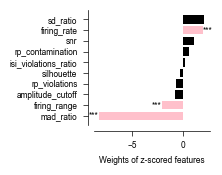

In [13]:
%%time

# save config
savefig_cfg = {"transparent": True, "dpi": 300}

# plot
fig, ax = plot_source_data(df)

# save figure
os.makedirs("figures/8_source_data/fig5g", exist_ok=True)
plt.savefig("figures/8_source_data/fig5g/fig5g.svg", bbox_inches="tight", **savefig_cfg)

# save source data
df.to_excel("figures/8_source_data/fig5g/fig5g.xlsx", index=False)

CPU times: user 13.4 ms, sys: 408 µs, total: 13.8 ms
Wall time: 13.4 ms


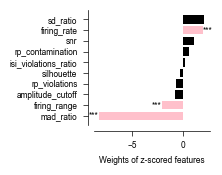

In [14]:
%%time

# check: replot from the saved source data
df = pd.read_excel("figures/8_source_data/fig5g/fig5g.xlsx")
fig, ax = plot_source_data(df)

## Experiment: log-transformed features

* features with a long-tailed distribution (firing rate, firing range, sd ratio, snr, mad ratio) are log-transformed before training and testing the model (paper Methods: "Log-transforming ... did not improve performance")
* precision and recall are cross-validated as in fig5e (100 random 75% train / 25% test splits); nothing is plotted

In [ ]:
%%time

# log-transform the features with a long-tailed distribution
dataset_log = data["dataset"].copy()
for feature in ["firing_rate", "firing_range", "sd_ratio", "snr", "mad_ratio"]:
    dataset_log[feature] = np.log(dataset_log[feature].values)
    assert np.isfinite(dataset_log[feature]).all(), f"{feature} log-transform is not finite"  # unit-test

# train & evaluate w/ cross-validation (raw log-transformed features, as in fig5e)
results_log = flcmodel.crossval_evaluate(dataset_log, seeds=model_prms["seeds"], scale_data=model_prms["scale_data"])
print(results_log["metric_stats"])